# 05 · Comparative Analysis: AI4I 2020 vs APS Scania

The two studies were modeled **independently**. Feature spaces, failure definitions and
data-generating processes differ, so no model is transferred across datasets and no claim
of cross-dataset generalization is made. What we compare is *how the same methodology
behaves* on two very different predictive-maintenance problems.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as C
from src import visualization as V
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = C.FIGURES_DIR
import json
R = C.RESULTS_DIR; FIGD = FIG / "comparison"
from src.models import ALGO_NAMES
from src.data_loader import load_ai4i, load_aps
ai = load_ai4i(); aps_tr, aps_te = load_aps()

## 1. Dataset characteristics

In [2]:
Xa = aps_tr.drop(columns="class")
chars = pd.DataFrame({
 "AI4I 2020": ["Milling machine process (synthetic)", "10,000 (80/20 split)", 6, 3, f"{ai['Machine failure'].mean():.2%}",
               f"{(ai['Machine failure']==0).sum()/ai['Machine failure'].sum():.0f}:1", "0%", "None", "Named physical sensors", "Any of 5 failure modes"],
 "APS Scania": ["Truck air pressure system (real fleet)", "60,000 train / 16,000 test (official)", 170, 2, f"{aps_tr['class'].mean():.2%} train / {aps_te['class'].mean():.2%} test",
                f"{(aps_tr['class']==0).sum()/aps_tr['class'].sum():.0f}:1", f"{Xa.isna().values.mean():.1%} of cells", "ac_000 code 0x7F000000; 1 constant column", "Anonymized counters + 7 histograms", "Failure attributed to APS component vs other components"]},
 index=["Domain","Records","Raw input features","Engineered features","Positive rate","Imbalance ratio","Missing values","Sentinels / quirks","Feature semantics","Positive class"])
display(chars)

,AI4I 2020,APS Scania
Domain,Milling machine process (synthetic),Truck air pressure system (real fleet)
Records,"10,000 (80/20 split)","60,000 train / 16,000 test (official)"
Raw input features,6,170
Engineered features,3,2
Positive rate,3.39%,1.67% train / 2.34% test
Imbalance ratio,28:1,59:1
Missing values,0%,8.3% of cells
Sentinels / quirks,None,ac_000 code 0x7F000000; 1 constant column
Feature semantics,Named physical sensors,Anonymized counters + 7 histograms
Positive class,Any of 5 failure modes,Failure attributed to APS component vs other c...


## 2. Model performance (test set, tuned models at OOF-selected thresholds)

recall        precision            f1        pr_auc       
dataset               AI4I    APS      AI4I    APS   AI4I    APS   AI4I    APS
algo                                                                          
Decision Tree        0.765  0.947     0.945  0.324  0.846  0.483  0.870  0.814
Gradient Boosting    0.794  0.965     1.000  0.440  0.885  0.605  0.905  0.928
KNN                  0.662  0.939     0.634  0.486  0.647  0.640  0.685  0.877
Logistic Regression  0.471  0.955     0.525  0.371  0.496  0.534  0.464  0.865
Random Forest        0.824  0.979     0.966  0.363  0.889  0.530  0.898  0.921

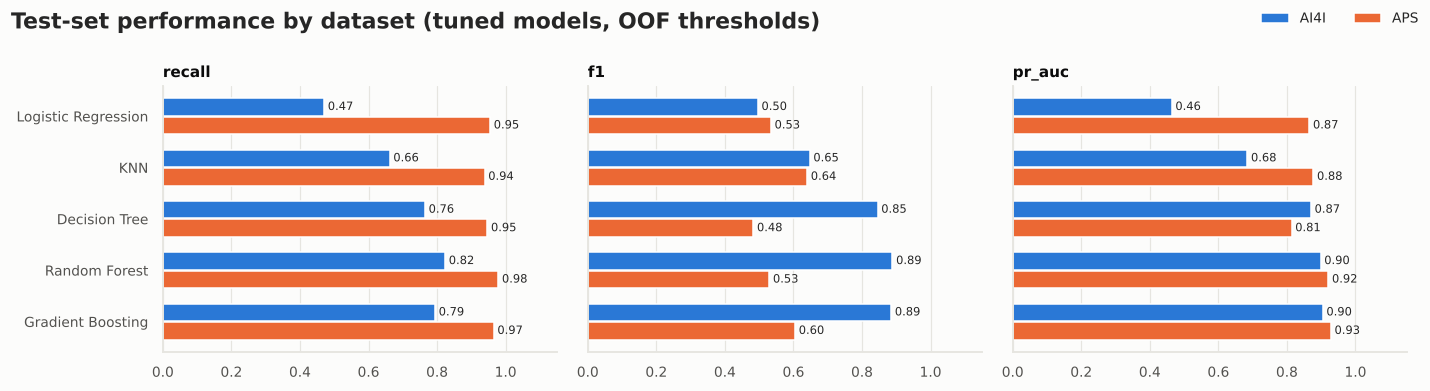

In [3]:
rows = []
for ds, rule in [("ai4i","oof_f1"),("aps","oof_cost")]:
    t = pd.read_csv(R / f"{ds}_test_results.csv"); t = t[t.threshold_rule == rule].copy()
    t["dataset"] = ds.upper(); t["algo"] = t.model.str.split("_").str[0]; rows.append(t)
perf = pd.concat(rows)
display(perf.pivot(index="algo", columns="dataset", values=["recall","precision","f1","pr_auc"]).rename(index=ALGO_NAMES).round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, ["recall", "f1", "pr_auc"]):
    pv = perf.pivot(index="algo", columns="dataset", values=m).reindex(list(ALGO_NAMES))
    yy = np.arange(len(pv))
    for j, (ds, col) in enumerate([("AI4I", V.SERIES[0]), ("APS", V.SERIES[1])]):
        ax.barh(yy + (j - 0.5) * 0.36, pv[ds], 0.34, color=col, label=ds)
        for i, v in enumerate(pv[ds]): ax.text(v, i + (j - 0.5) * 0.36, f" {v:.2f}", va="center", fontsize=7.5)
    ax.set_title(m, fontsize=10); ax.set_xlim(0, 1.15); ax.grid(axis="y", visible=False)
axes[0].set_yticks(yy); axes[0].set_yticklabels(pv.index.map(ALGO_NAMES)); axes[0].invert_yaxis(); fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
fig.suptitle("Test-set performance by dataset (tuned models, OOF thresholds)", x=0.01, ha="left", fontweight="bold"); fig.tight_layout()
V.save(fig, FIGD / "01_performance_by_dataset.png"); plt.show()

## 3. Effect of imbalance handling (CV, default hyperparameters)

In [4]:
rows = []
for ds in ["ai4i","aps"]:
    s = pd.read_csv(R / f"{ds}_strategy_cv.csv"); s["dataset"] = ds.upper(); rows.append(s)
st = pd.concat(rows, ignore_index=True)
# KNN has no class-weight variant, so averages use the 4 algorithms that support every strategy
g = st[st.algo != "knn"].groupby(["dataset","strategy"])[["oof_pr_auc","cv_recall","cv_f1"]].mean().round(3)
print("mean over LR, DT, RF, GB (KNN excluded: no class-weight variant)"); display(g)
print("best strategy per algorithm (by OOF PR-AUC):")
display(st.loc[st.groupby(["dataset","algo"]).oof_pr_auc.idxmax(), ["dataset","algo","strategy","oof_pr_auc"]].round(3))

mean over LR, DT, RF, GB (KNN excluded: no class-weight variant)


oof_pr_auc  cv_recall  cv_f1
dataset strategy                                  
AI4I    class_weight       0.719      0.830  0.652
        none               0.747      0.683  0.746
        ros                0.722      0.829  0.661
        smote              0.599      0.837  0.494
APS     class_weight       0.705      0.788  0.628
        none               0.766      0.694  0.753
        ros                0.722      0.754  0.666
        smote              0.697      0.810  0.650

best strategy per algorithm (by OOF PR-AUC):


,dataset,algo,strategy,oof_pr_auc
7,AI4I,dtree,none,0.688
15,AI4I,gb,none,0.909
4,AI4I,knn,none,0.515
0,AI4I,logreg,none,0.496
11,AI4I,rf,none,0.895
26,APS,dtree,none,0.500
36,APS,gb,ros,0.896
23,APS,knn,none,0.650
19,APS,logreg,none,0.819
30,APS,rf,none,0.875


## 4. Computational requirements

fit_time_s         predict_ms_per_1k          
dataset                   AI4I     APS              AI4I       APS
algo                                                              
Decision Tree            0.037   9.578             4.065     5.638
Gradient Boosting        4.050  16.396             6.245    10.129
KNN                      0.023   2.189            67.938  2999.569
Logistic Regression      0.030   3.159             3.813     6.004
Random Forest            1.549  53.246            38.389    11.539

dataset,search time (s) AI4I,search time (s) APS
algo,,
Decision Tree,7.0,321.0
Gradient Boosting,403.0,2763.0
KNN,10.0,970.0
Logistic Regression,8.0,60.0
Random Forest,188.0,671.0


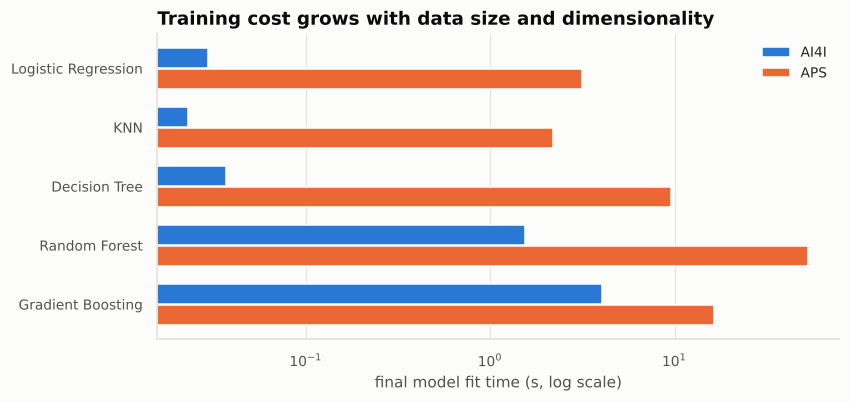

In [5]:
tm = perf.pivot(index="algo", columns="dataset", values=["fit_time_s","predict_ms_per_1k"]).rename(index=ALGO_NAMES).round(3)
display(tm)
srch = pd.concat([pd.read_csv(R / f"{ds}_tuned_cv.csv").assign(dataset=ds.upper()) for ds in ["ai4i","aps"]])
display(srch.pivot(index="algo", columns="dataset", values="search_time_s").rename(index=ALGO_NAMES).round(0).rename(columns=lambda c: f"search time (s) {c}"))
fig, ax = plt.subplots(figsize=(8, 3.6)); pv = perf.pivot(index="algo", columns="dataset", values="fit_time_s").reindex(list(ALGO_NAMES)); yy = np.arange(len(pv))
for j, (ds, col) in enumerate([("AI4I", V.SERIES[0]), ("APS", V.SERIES[1])]):
    ax.barh(yy + (j - 0.5) * 0.36, pv[ds], 0.34, color=col, label=ds)
ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(pv.index.map(ALGO_NAMES)); ax.invert_yaxis(); ax.legend()
ax.set(xlabel="final model fit time (s, log scale)", title="Training cost grows with data size and dimensionality"); ax.grid(axis="y", visible=False)
V.save(fig, FIGD / "02_training_time_by_dataset.png"); plt.show()

## 5. Most important features

In [6]:
for ds in ["ai4i","aps"]:
    s = pd.read_csv(R / f"{ds}_shap_mean_abs.csv", index_col=0)
    print(ds.upper(), "- top 8 by mean |SHAP|:"); display(s.head(8).round(4))

AI4I - top 8 by mean |SHAP|:


,mean_abs_shap
Rotational speed [rpm],0.3487
Tool wear [min],0.3473
temp_diff [K],0.3432
power [W],0.1367
strain [Nm*min],0.1154
Type_L,0.0144
Torque [Nm],0.0136
Process temperature [K],0.0051


APS - top 8 by mean |SHAP|:


,mean_abs_shap
ck_000,1.6376
aa_000,1.2708
ci_000,0.6351
bs_000,0.5018
am_0,0.4283
cb_000,0.4190
ay_008,0.4190
ag_002,0.3787


## 6. Best models

In [7]:
for ds in ["ai4i","aps"]:
    b = json.loads((R / f"{ds}_best_model.json").read_text()); print(ds.upper(), "->", ALGO_NAMES[b["algo"]], "| strategy:", b["strategy"], "| threshold:", b["threshold"], "|", b["criterion"])

AI4I -> Gradient Boosting | strategy: none | threshold: 0.58 | highest OOF F1 at the OOF-selected threshold (tie-break: OOF PR-AUC)
APS -> Gradient Boosting | strategy: ros | threshold: 0.0025 | lowest OOF Scania cost at the OOF-selected threshold (tie-break: OOF PR-AUC)


## 7. Summary

- **Same winners, different reasons.** Gradient Boosting was selected on both datasets, with
  Random Forest effectively tied. On AI4I, the ensembles win because failures are threshold and
  interaction rules. On APS, they win because they handle 170 skewed, redundant features with
  informative missingness.
- **Linear models split sharply:** Logistic Regression reaches PR-AUC 0.865 on APS but only 0.464
  on AI4I, where no single monotonic combination of sensors describes the failure modes.
- **Imbalance:** resampling helped only APS Gradient Boosting. On AI4I, every strategy lowered
  PR-AUC (SMOTE most of all).
- **Thresholds:** AI4I's F1-optimal thresholds sit at 0.19–0.58. APS's cost-optimal thresholds
  are 0.0025–0.04 because one missed failure costs as much as 50 false alarms. The business
  cost, not the model, sets the operating point.
- **Data quality** dominates APS preprocessing (missingness, a hidden sentinel, skew). On AI4I,
  domain feature engineering matters most (+0.13 PR-AUC for GB).
- **Compute:** APS models take 10–1,000× longer to fit. KNN inference (3 s per 1,000 trucks)
  and classic gradient boosting training (187 s) become the practical bottlenecks.
- **No cross-dataset claims:** different inputs, labels and generating processes. What transfers
  is the methodology.